# Binary `isBird` classifier and TensorFlow Lite export

Trains a whole-image **bird / not-bird** classifier for the Raspberry Pi receiver and
exports float32 and fully quantised uint8 TensorFlow Lite models.

The original positive class comes from `Training Manifest/bird_training_manifest.csv`.
That CSV remains authoritative for its exact image IDs, paths, source datasets, and
existing `model_split` assignments.

Baseline negatives come from categories whose iNaturalist taxonomy `class` is not `Aves`.
Negative categories, rather than individual images, are assigned to splits, so an
iNaturalist negative taxon cannot leak between train, validation, and test.

Labelled ESP32 captures add both real camera birds and real camera non-birds. A manifest row
with `bird_present=false` / `binary_label=0` supplies a feeder-camera empty-frame negative; a
row with `bird_present=true` / `binary_label=1` remains positive even when its species is
`Unknown`. Stale absolute manifest paths are ignored: `image_relative_path` is resolved below
the configured relocated capture root. Whole capture dates are kept in one split to prevent
adjacent burst frames from leaking across train, validation, and test.

Pixel scaling is inside the model. Exported models accept geometrically preprocessed RGB
pixels in the 0-255 range: float32 for `model_float32.tflite` and uint8 for
`model_int8.tflite`.


## 1. Configuration

In [1]:
import platform
import sys

print("Python:", sys.executable)
print("System:", platform.system(), platform.release())

Python: /home/joe/venvs/ESPclassifier/bin/python
System: Linux 6.6.87.2-microsoft-standard-WSL2


In [2]:
# ---- Experiment -------------------------------------------------------------
PREPROCESSING = "letterbox"  # "letterbox" | "stretch" | "center_crop"
IMG_SIZE = 224
RUN_NAME = None  # default: isbird_<preprocessing>_<size>_<timestamp>

# ---- Authoritative bird manifest --------------------------------------------
# Stored image_path is tried first. These roots are fallbacks for a relocated
# dataset; image_relative_path from the manifest supplies the path below each root.
CUB_PHOTO_ROOT = r"/mnt/e/Datasets/CUB_200/CUB_200_2011/images"
INATURALIST_PHOTO_ROOT = r"/mnt/e/Datasets/iNaturalist/train_mini/train_mini"

# ---- iNaturalist non-Aves negatives -----------------------------------------
INATURALIST_METADATA = r"/mnt/e/Datasets/iNaturalist/train_mini/train_mini.json/train_mini.json"
NEGATIVE_TO_POSITIVE_RATIO = 1.0  # per split for iNaturalist negatives
VERIFY_ALL_FILES = True  # False is useful only for small dry-run validation

# ---- Labelled ESP32 captures -------------------------------------------------
# The manifest's absolute image_path values refer to the old location. Paths are
# rebuilt from this relocated root plus image_relative_path. A Windows path is
# automatically mapped to /mnt/<drive>/... when the notebook runs under WSL.
ESP32_CAPTURE_ROOT = r"/mnt/e/Datasets/ESP32_capture"
ESP32_CAPTURE_MANIFEST = None  # default: ../esp32_capture_manifest.csv
ESP32_VALIDATION_DATES = ("2026-10-05",)
ESP32_TEST_DATES = ("2026-10-07",)
ESP32_TRAIN_LIMIT_PER_LABEL = 200  # None uses every training-date capture

# ---- Model -------------------------------------------------------------------
BACKBONE_ALPHA = 1.0  # MobileNetV2 width: 0.35 / 0.5 / 0.75 / 1.0
WEIGHTS = "imagenet"
DROPOUT = 0.2

# ---- Training ---------------------------------------------------------------
BATCH_SIZE = 32
HEAD_EPOCHS = 10
FINE_TUNE_EPOCHS = 10  # 0 to skip
FINE_TUNE_LAYERS = 40
HEAD_LR = 1e-3
FINE_TUNE_LR = 1e-5
EARLY_STOP_PATIENCE = 4
AUGMENT_FLIP = True
AUGMENT_COLOR = True
SEED = 1234

# ---- Evaluation/export -------------------------------------------------------
# Select the validation threshold with the best recall while satisfying this FPR.
MAX_VALIDATION_FALSE_POSITIVE_RATE = 0.05
MAX_ESP32_VALIDATION_FALSE_POSITIVE_RATE = 0.05
REPRESENTATIVE_IMAGES = 300
TFLITE_EVAL_LIMIT = None  # None = all validation/test images

# Set for a quick pipeline check. This samples up to N records from each label
# and source in every split.
LIMIT_PER_CLASS_PER_SPLIT = None

## 2. Load bird manifest

`image_path` is used as stored when it exists. A Windows drive path is also mapped to its
normal WSL `/mnt/<drive>/...` form. Only if neither exists is the configured source root
combined with `image_relative_path`. This is path resolution, not image discovery.

In [3]:
import os
print(os.name)                      
print(os.listdir("/mnt"))            
print(os.listdir("/mnt/e"))          
print(os.listdir("/mnt/e/Datasets"))

posix
['e', 'wsl', 'c', 'wslg']
['$RECYCLE.BIN', 'applications', 'Datasets', 'old files from laptop', 'System Volume Information']
['AudioMNIST-master', 'BirdClef', 'bridge_nbconvert.log', 'Celeb-DF-v2', 'CIFAKE', 'CUB_200', 'DF40_test', 'DF40_train', 'ESP32_capture', 'FaceForensics++', 'iNaturalist', 'iNaturalist_CUB200_bird_bridge.ipynb', 'make_inaturalist_cub200_bridge_notebook.py', 'sa_fari', '__pycache__']


In [3]:
import hashlib
import json
import math
import os
import random
import re
import shutil
import time
from datetime import datetime
from pathlib import Path, PurePosixPath, PureWindowsPath

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

keras = tf.keras

for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

_candidates = [Path.cwd(), Path.cwd() / "Models"]
MODELS_DIR = next((p for p in _candidates if (p / "Training Manifest").is_dir()), None)
if MODELS_DIR is None:
    raise FileNotFoundError(f"'Training Manifest' folder not found from {Path.cwd()}")

MANIFEST_DIR = MODELS_DIR / "Training Manifest"
BIRD_MANIFEST_CSV = MANIFEST_DIR / "bird_training_manifest.csv"
BIRD_SUMMARY_JSON = MANIFEST_DIR / "bird_training_summary.json"
RUN_NAME = RUN_NAME or f"isbird_{PREPROCESSING}_{IMG_SIZE}_{datetime.now():%Y%m%d_%H%M%S}"
RUN_DIR = MODELS_DIR / "runs" / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=False)


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


def existing_path(*candidates):
    for candidate in candidates:
        if candidate and Path(candidate).is_file():
            return str(Path(candidate))
    return None


def windows_path_to_wsl(value):
    path = PureWindowsPath(str(value))
    if not path.drive:
        return None
    drive = path.drive.rstrip(":").lower()
    return str(Path("/mnt") / drive / Path(*path.parts[1:]))


def existing_directory(*candidates):
    for candidate in candidates:
        if candidate and Path(candidate).is_dir():
            return Path(candidate)
    return None


esp32_manifest_config = ESP32_CAPTURE_MANIFEST or MODELS_DIR.parent / "esp32_capture_manifest.csv"
ESP32_MANIFEST_CSV = existing_path(
    esp32_manifest_config, windows_path_to_wsl(esp32_manifest_config)
)
if ESP32_MANIFEST_CSV is None:
    raise FileNotFoundError(f"ESP32 capture manifest not found: {esp32_manifest_config}")
ESP32_MANIFEST_CSV = Path(ESP32_MANIFEST_CSV)

ESP32_CAPTURE_ROOT_RESOLVED = existing_directory(
    ESP32_CAPTURE_ROOT, windows_path_to_wsl(ESP32_CAPTURE_ROOT)
)
if ESP32_CAPTURE_ROOT_RESOLVED is None:
    raise FileNotFoundError(f"ESP32 capture root not found: {ESP32_CAPTURE_ROOT}")


bird_summary = json.loads(BIRD_SUMMARY_JSON.read_text(encoding="utf-8"))
bird_manifest_sha = sha256_file(BIRD_MANIFEST_CSV)
expected_sha = bird_summary["outputs"]["training_manifest_sha256"]
if bird_manifest_sha != expected_sha:
    raise ValueError("bird_training_manifest.csv does not match its summary hash; rebuild it.")

bird_raw = pd.read_csv(BIRD_MANIFEST_CSV, encoding="utf-8", keep_default_na=False)
required = {"image_id", "image_path", "image_relative_path", "source_dataset", "model_split"}
if missing_columns := required - set(bird_raw.columns):
    raise ValueError(f"Bird manifest is missing columns: {sorted(missing_columns)}")
if set(bird_raw["model_split"]) - {"train", "validation", "test"}:
    raise ValueError("Bird manifest contains an unsupported model_split.")

photo_roots = {
    "cub_200_2011": CUB_PHOTO_ROOT,
    "inaturalist": INATURALIST_PHOTO_ROOT,
}


def resolve_bird_path(row):
    stored = str(row.image_path)
    wsl_stored = windows_path_to_wsl(stored)
    root = photo_roots.get(row.source_dataset)
    relative_parts = PurePosixPath(str(row.image_relative_path)).parts
    relocated = str(Path(root).joinpath(*relative_parts[1:])) if root and len(relative_parts) > 1 else None
    if not VERIFY_ALL_FILES:
        # Avoid tens of thousands of slow stat calls over WSL's mounted-drive bridge.
        # The selected dry-run rows are still verified after dataset assembly.
        if os.name != "nt" and wsl_stored:
            return wsl_stored
        return stored or relocated
    resolved = existing_path(stored, wsl_stored, relocated)
    return resolved or stored


bird_frame = pd.DataFrame({
    "path": [resolve_bird_path(row) for row in bird_raw.itertuples(index=False)],
    "label": np.ones(len(bird_raw), dtype=np.int32),
    "class_name": "bird",
    "model_split": bird_raw["model_split"],
    "source_dataset": bird_raw["source_dataset"],
    "group_id": "bird_taxon:" + bird_raw["canonical_taxon_id"].astype(str),
    "original_id": bird_raw["image_id"].astype(str),
})

if VERIFY_ALL_FILES:
    missing_birds = bird_frame.loc[~bird_frame["path"].map(os.path.isfile), "path"].tolist()
    if missing_birds:
        raise FileNotFoundError(
            f"{len(missing_birds):,} of {len(bird_frame):,} manifest bird images were not found. "
            "Mount the dataset drive or update the two photo roots. First missing:\n  "
            + "\n  ".join(missing_birds[:5])
        )
else:
    print("VERIFY_ALL_FILES=False: deferring checks until after dry-run sampling.")

print(f"Loaded {len(bird_frame):,} bird images from the verified training manifest.")
bird_frame.groupby(["model_split", "source_dataset"]).size().unstack(fill_value=0)

I0000 00:00:1791668185.234557    1832 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791668185.283553    1832 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791668186.899886    1832 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Loaded 19,607 bird images from the verified training manifest.


source_dataset,cub_200_2011,inaturalist
model_split,,
test,5293,895
train,4290,7160
validation,1074,895


## 3. Build category-held-out iNaturalist negatives

The COCO-style metadata is used directly. Categories with `class == "Aves"` are excluded,
remaining category IDs are deterministically assigned to exactly one split, and images are
sampled in round-robin category order. The target count in each split is based on the bird
manifest count for that split.

In [4]:
metadata_path = Path(INATURALIST_METADATA)
image_root = Path(INATURALIST_PHOTO_ROOT)
if not metadata_path.is_file():
    raise FileNotFoundError(f"iNaturalist metadata not found: {metadata_path}")
if not image_root.is_dir():
    raise FileNotFoundError(f"iNaturalist image root not found: {image_root}")

with metadata_path.open(encoding="utf-8") as handle:
    inat = json.load(handle)

categories = pd.DataFrame(inat["categories"])
negative_categories = categories[categories["class"] != "Aves"].copy()
if negative_categories.empty:
    raise ValueError("No non-Aves categories were found in the iNaturalist metadata.")

split_names = ("train", "validation", "test")
bird_split_counts = bird_frame["model_split"].value_counts().reindex(split_names).astype(int)
split_fractions = bird_split_counts / bird_split_counts.sum()


def assign_groups_to_splits(group_ids, fractions, seed):
    group_ids = np.asarray(sorted(set(group_ids)))
    rng = np.random.default_rng(seed)
    rng.shuffle(group_ids)
    raw_counts = np.asarray(fractions, dtype=float) * len(group_ids)
    counts = np.floor(raw_counts).astype(int)
    for index in np.argsort(-(raw_counts - counts))[: len(group_ids) - counts.sum()]:
        counts[index] += 1
    assignments = {}
    start = 0
    for split_name, count in zip(split_names, counts):
        for group_id in group_ids[start : start + count]:
            assignments[group_id] = split_name
        start += count
    return assignments


category_split = assign_groups_to_splits(
    negative_categories["id"].astype(int), split_fractions.to_numpy(), SEED
)
category_lookup = negative_categories.set_index("id").to_dict("index")
annotation_category = {
    int(row["image_id"]): int(row["category_id"])
    for row in inat["annotations"]
    if int(row["category_id"]) in category_split
}
negative_records = []
for image in inat["images"]:
    image_id = int(image["id"])
    category_id = annotation_category.get(image_id)
    if category_id is None:
        continue
    category = category_lookup[category_id]
    negative_records.append({
        "image_id": image_id,
        "category_id": category_id,
        "category_name": category.get("name", str(category_id)),
        "category_class": category.get("class", ""),
        "image_dir_name": category["image_dir_name"],
        "file_name": image["file_name"],
        "model_split": category_split[category_id],
    })

del annotation_category, inat
negative_pool = pd.DataFrame(negative_records)
if negative_pool.empty:
    raise ValueError("No usable non-Aves images were joined from iNaturalist metadata.")


def balanced_category_sample(frame, count, seed):
    if count > len(frame):
        raise ValueError(f"Requested {count:,} negatives from a pool of {len(frame):,}.")
    shuffled = frame.sample(frac=1, random_state=seed).copy()
    shuffled["within_category_rank"] = shuffled.groupby("category_id", sort=False).cumcount()
    shuffled["tie_break"] = np.random.default_rng(seed).random(len(shuffled))
    sampled = shuffled.sort_values(
        ["within_category_rank", "tie_break", "category_id"]
    ).head(count)
    return sampled.drop(columns=["within_category_rank", "tie_break"])


baseline_parts = []
for split_index, split_name in enumerate(split_names):
    target = int(math.ceil(bird_split_counts[split_name] * NEGATIVE_TO_POSITIVE_RATIO))
    pool = negative_pool[negative_pool["model_split"] == split_name]
    baseline_parts.append(balanced_category_sample(pool, target, SEED + split_index))
baseline_negative = pd.concat(baseline_parts, ignore_index=True)


def negative_image_path(row):
    # image_dir_name is authoritative metadata; basename avoids duplicating train_mini/.
    return str(image_root / row.image_dir_name / PurePosixPath(row.file_name).name)


baseline_frame = pd.DataFrame({
    "path": [negative_image_path(row) for row in baseline_negative.itertuples(index=False)],
    "label": np.zeros(len(baseline_negative), dtype=np.int32),
    "class_name": "not_bird",
    "model_split": baseline_negative["model_split"],
    "source_dataset": "inaturalist_non_aves",
    "group_id": "inat_category:" + baseline_negative["category_id"].astype(str),
    "original_id": "inaturalist:" + baseline_negative["image_id"].astype(str),
})

missing_negatives = baseline_frame.loc[~baseline_frame["path"].map(os.path.isfile), "path"].tolist()
if missing_negatives:
    raise FileNotFoundError(
        f"{len(missing_negatives):,} sampled iNaturalist negatives were missing. First missing:\n  "
        + "\n  ".join(missing_negatives[:5])
    )

category_split_check = baseline_negative.groupby("category_id")["model_split"].nunique()
assert category_split_check.max() == 1, "A negative category leaked between splits."
print(
    f"Selected {len(baseline_frame):,} baseline non-birds from "
    f"{baseline_negative['category_id'].nunique():,} held-out categories."
)
baseline_frame.groupby("model_split").size().reindex(split_names)

Selected 19,607 baseline non-birds from 8,514 held-out categories.


model_split
train         11450
validation     1969
test           6188
dtype: int64

## 4. Load labelled ESP32 captures

`image_path` in the capture manifest points at the old dataset root, so it is deliberately
not used. Every selected file is resolved as `ESP32_CAPTURE_ROOT / image_relative_path`.

Only rows explicitly marked `labeled` with a binary label are accepted. `binary_label=0`
(`bird_present=false`, shown as `No bird` in the manifest) provides the feeder-camera empty
frames. `binary_label=1` is a bird whether `species` names a species or is `Unknown`. A capture
date is parsed from each preserved filename and used as `group_id`; configured validation and test
dates are held out whole, while every other date belongs to training. The training subset is
sampled reproducibly per label, but held-out dates remain intact for camera-domain metrics.


In [5]:
ESP32_REQUIRED_COLUMNS = {
    "record_id", "image_relative_path", "filename", "is_labeled",
    "manual_label_status", "binary_label", "image_sha256",
}
ESP32_DATE_PATTERNS = (
    re.compile(r"^(\d{4})-(\d{2})-(\d{2})"),
    re.compile(r"^capture_(\d{4})(\d{2})(\d{2})T"),
    re.compile(r"^(\d{4})-(\d{2})(\d{2})\d{6}"),
    re.compile(r"^(\d{4})(\d{2})(\d{2})\d{6}"),
)


def capture_date_from_filename(filename):
    filename = str(filename).strip()
    for pattern in ESP32_DATE_PATTERNS:
        if match := pattern.match(filename):
            return "-".join(match.groups())
    raise ValueError(f"Cannot infer an ESP32 capture date from filename: {filename!r}")


def relocated_esp32_path(relative_value):
    relative = PureWindowsPath(str(relative_value).strip())
    if relative.drive or relative.root or ".." in relative.parts:
        raise ValueError(f"Unsafe ESP32 image_relative_path: {relative_value!r}")
    return str(ESP32_CAPTURE_ROOT_RESOLVED.joinpath(*relative.parts))


esp32_manifest_sha = sha256_file(ESP32_MANIFEST_CSV)
esp32_raw = pd.read_csv(ESP32_MANIFEST_CSV, encoding="utf-8", keep_default_na=False)
if missing_columns := ESP32_REQUIRED_COLUMNS - set(esp32_raw.columns):
    raise ValueError(f"ESP32 manifest is missing columns: {sorted(missing_columns)}")

esp32_labels = pd.to_numeric(esp32_raw["binary_label"], errors="coerce")
esp32_confirmed_mask = (
    esp32_raw["is_labeled"].astype(str).str.strip().str.lower().isin({"true", "1", "yes"})
    & esp32_raw["manual_label_status"].astype(str).str.strip().str.lower().eq("labeled")
    & esp32_labels.isin([0, 1])
)
esp32_confirmed = esp32_raw.loc[esp32_confirmed_mask].copy()
esp32_confirmed["label"] = esp32_labels.loc[esp32_confirmed_mask].astype(np.int32)
if esp32_confirmed.empty:
    raise ValueError("The ESP32 manifest has no confirmed binary labels.")

for column in ("record_id", "image_relative_path", "image_sha256"):
    if esp32_confirmed[column].eq("").any():
        raise ValueError(f"Confirmed ESP32 rows contain blank {column} values.")
    if esp32_confirmed[column].duplicated().any():
        raise ValueError(f"Confirmed ESP32 rows contain duplicate {column} values.")

esp32_confirmed["capture_date"] = esp32_confirmed["filename"].map(
    capture_date_from_filename
)
validation_dates = set(ESP32_VALIDATION_DATES)
test_dates = set(ESP32_TEST_DATES)
if validation_dates & test_dates:
    raise ValueError("ESP32 validation and test dates overlap.")
available_dates = set(esp32_confirmed["capture_date"])
if unknown_dates := (validation_dates | test_dates) - available_dates:
    raise ValueError(f"Configured ESP32 split dates are absent: {sorted(unknown_dates)}")


def esp32_split(capture_date):
    if capture_date in validation_dates:
        return "validation"
    if capture_date in test_dates:
        return "test"
    return "train"


esp32_confirmed["model_split"] = esp32_confirmed["capture_date"].map(esp32_split)
esp32_all_frame = pd.DataFrame({
    "path": esp32_confirmed["image_relative_path"].map(relocated_esp32_path),
    "label": esp32_confirmed["label"],
    "class_name": np.where(esp32_confirmed["label"].eq(1), "bird", "not_bird"),
    "model_split": esp32_confirmed["model_split"],
    "source_dataset": "esp32_capture",
    "group_id": "esp32_date:" + esp32_confirmed["capture_date"],
    "original_id": "esp32:" + esp32_confirmed["record_id"].astype(str),
})

missing_esp32 = esp32_all_frame.loc[
    ~esp32_all_frame["path"].map(os.path.isfile), "path"
].tolist()
if missing_esp32:
    raise FileNotFoundError(
        f"{len(missing_esp32):,} ESP32 images were not found below the relocated root. "
        "First missing:\n  " + "\n  ".join(missing_esp32[:5])
    )

esp32_parts = []
for split_name in split_names:
    split_part = esp32_all_frame[esp32_all_frame["model_split"] == split_name]
    if split_name == "train" and ESP32_TRAIN_LIMIT_PER_LABEL is not None:
        for label in (0, 1):
            label_part = split_part[split_part["label"] == label]
            esp32_parts.append(label_part.sample(
                n=min(ESP32_TRAIN_LIMIT_PER_LABEL, len(label_part)),
                random_state=SEED + 200 + label,
            ))
    else:
        esp32_parts.append(split_part)
esp32_frame = pd.concat(esp32_parts, ignore_index=True)

esp32_group_splits = esp32_frame.groupby("group_id")["model_split"].nunique()
if len(esp32_group_splits) and esp32_group_splits.max() > 1:
    raise ValueError("An ESP32 capture date occurs in more than one split.")

esp32_counts_before_limit = (
    esp32_all_frame.groupby(["model_split", "label"]).size().unstack(fill_value=0)
    .reindex(index=split_names, columns=[0, 1], fill_value=0)
)
esp32_counts_selected = (
    esp32_frame.groupby(["model_split", "label"]).size().unstack(fill_value=0)
    .reindex(index=split_names, columns=[0, 1], fill_value=0)
)
print(
    f"ESP32 manifest: {len(esp32_raw):,} rows; "
    f"{len(esp32_confirmed):,} confirmed; "
    f"{len(esp32_raw) - len(esp32_confirmed):,} rejected."
)
print("Resolved ESP32 root:", ESP32_CAPTURE_ROOT_RESOLVED)
print("ESP32 counts before the training cap:", esp32_counts_before_limit, sep="\n")
print("ESP32 counts selected:", esp32_counts_selected, sep="\n")


ESP32 manifest: 3,260 rows; 3,254 confirmed; 6 rejected.
Resolved ESP32 root: /mnt/e/Datasets/ESP32_capture
ESP32 counts before the training cap:
label          0     1
model_split           
train        220   878
validation    37   254
test         620  1245
ESP32 counts selected:
label          0     1
model_split           
train        200   200
validation    37   254
test         620  1245


## 5. Assemble and validate the binary dataset

In [6]:
if LIMIT_PER_CLASS_PER_SPLIT:
    limited_birds, limited_baseline, limited_esp32 = [], [], []
    for split_index, split_name in enumerate(split_names):
        for source_frame, destination in (
            (bird_frame, limited_birds), (baseline_frame, limited_baseline)
        ):
            part = source_frame[source_frame["model_split"] == split_name]
            destination.append(part.sample(
                n=min(LIMIT_PER_CLASS_PER_SPLIT, len(part)),
                random_state=SEED + split_index,
            ))
        for label in (0, 1):
            part = esp32_frame[
                (esp32_frame["model_split"] == split_name) & (esp32_frame["label"] == label)
            ]
            limited_esp32.append(part.sample(
                n=min(LIMIT_PER_CLASS_PER_SPLIT, len(part)),
                random_state=SEED + 100 + 2 * split_index + label,
            ))
    bird_frame = pd.concat(limited_birds, ignore_index=True)
    baseline_frame = pd.concat(limited_baseline, ignore_index=True)
    esp32_frame = pd.concat(limited_esp32, ignore_index=True)
    print("LIMIT_PER_CLASS_PER_SPLIT is set: this is a dry run.")

dataset_frame = pd.concat(
    [bird_frame, baseline_frame, esp32_frame], ignore_index=True
)
dataset_frame["label"] = dataset_frame["label"].astype(np.int32)

if not VERIFY_ALL_FILES:
    missing_selected = dataset_frame.loc[
        ~dataset_frame["path"].map(os.path.isfile), "path"
    ].tolist()
    if missing_selected:
        raise FileNotFoundError(
            f"{len(missing_selected):,} selected dry-run images were missing. First missing:\n  "
            + "\n  ".join(missing_selected[:5])
        )

assert set(dataset_frame["label"]) == {0, 1}
assert set(dataset_frame["model_split"]) == set(split_names)
if dataset_frame["path"].duplicated().any():
    duplicates = dataset_frame.loc[dataset_frame["path"].duplicated(False), "path"].head().tolist()
    raise ValueError(f"Image paths occur more than once: {duplicates}")

# The existing bird manifest deliberately preserves its own splits. Leakage checks here
# apply to the newly created negative groups and to both labels from each ESP32 date.
negative_groups = dataset_frame[dataset_frame["label"] == 0].groupby("group_id")["model_split"].nunique()
if len(negative_groups) and negative_groups.max() > 1:
    raise ValueError("A negative group occurs in more than one split.")
esp32_group_splits = (
    dataset_frame[dataset_frame["source_dataset"] == "esp32_capture"]
    .groupby("group_id")["model_split"].nunique()
)
if len(esp32_group_splits) and esp32_group_splits.max() > 1:
    raise ValueError("An ESP32 capture date occurs in more than one split.")

splits = {
    name: dataset_frame[dataset_frame["model_split"] == name]
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
    for name in split_names
}
for name, frame in splits.items():
    if set(frame["label"]) != {0, 1}:
        raise ValueError(f"{name} must contain both labels.")

dataset_manifest_path = RUN_DIR / "isbird_dataset_manifest.csv"
dataset_frame.to_csv(dataset_manifest_path, index=False)
dataset_manifest_sha = sha256_file(dataset_manifest_path)

distribution = (
    dataset_frame.groupby(["model_split", "class_name", "source_dataset"])
    .size().rename("images").reset_index()
)
print("Run folder:", RUN_DIR)
print("Dataset SHA-256:", dataset_manifest_sha)
distribution

Run folder: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/runs/isbird_letterbox_224_20261010_173627
Dataset SHA-256: 0ccfd57de4bf8cb79ff7d972ecec932dae095ee2a61968e678f9f65ab4c0c40f


,model_split,class_name,source_dataset,images
0,test,bird,cub_200_2011,5293
1,test,bird,esp32_capture,1245
2,test,bird,inaturalist,895
3,test,not_bird,esp32_capture,620
4,test,not_bird,inaturalist_non_aves,6188
5,train,bird,cub_200_2011,4290
6,train,bird,esp32_capture,200
7,train,bird,inaturalist,7160
8,train,not_bird,esp32_capture,200
9,train,not_bird,inaturalist_non_aves,11450


## 6. Preprocessing and input pipeline

Each geometric function returns `IMG_SIZE × IMG_SIZE × 3` float32 RGB in the 0-255 range.
Augmentation is applied only by the training dataset and is not embedded in exported
inference graphs.

I0000 00:00:1791668640.477922    1832 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3582 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


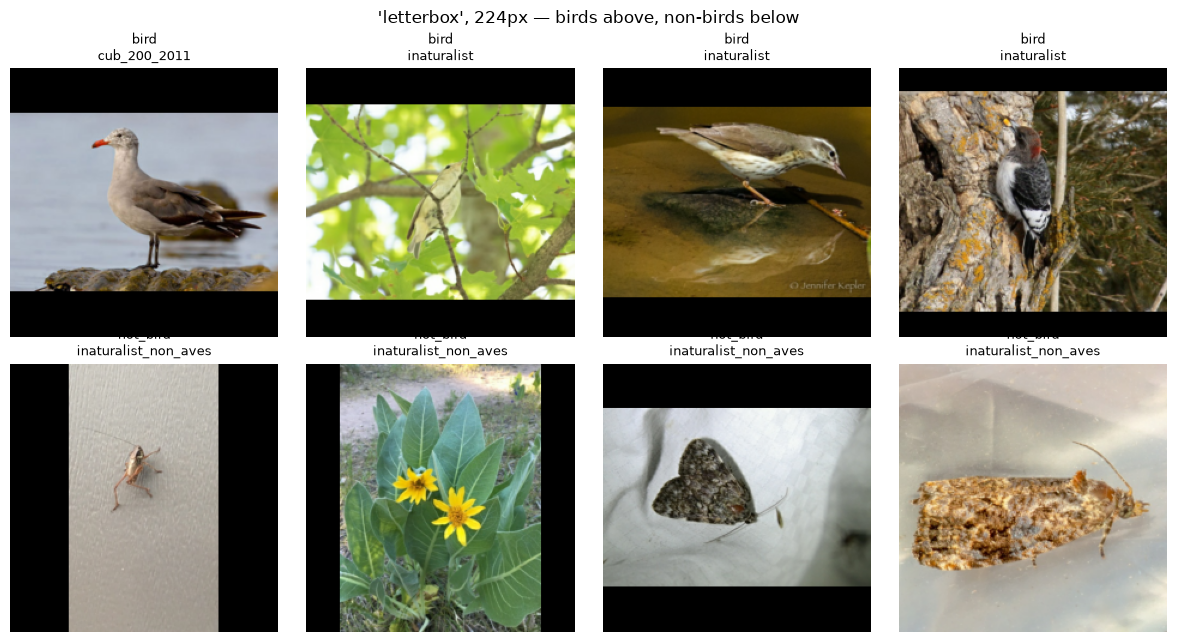

In [7]:
def letterbox(image, size):
    return tf.image.resize_with_pad(image, size, size, antialias=True)


def stretch(image, size):
    return tf.image.resize(image, [size, size], antialias=True)


def center_crop(image, size):
    shape = tf.cast(tf.shape(image)[:2], tf.float32)
    scale = tf.cast(size, tf.float32) / tf.reduce_min(shape)
    new_hw = tf.maximum(tf.cast(tf.math.ceil(shape * scale), tf.int32), size)
    image = tf.image.resize(image, new_hw, antialias=True)
    return tf.image.resize_with_crop_or_pad(image, size, size)


PREPROCESSORS = {"letterbox": letterbox, "stretch": stretch, "center_crop": center_crop}
if PREPROCESSING not in PREPROCESSORS:
    raise ValueError(f"Unknown PREPROCESSING={PREPROCESSING!r}; choose {sorted(PREPROCESSORS)}")
preprocess_fn = PREPROCESSORS[PREPROCESSING]


def load_image(path):
    image = tf.io.decode_image(
        tf.io.read_file(path), channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = preprocess_fn(tf.cast(image, tf.float32), IMG_SIZE)
    image = tf.clip_by_value(image, 0.0, 255.0)
    image.set_shape([IMG_SIZE, IMG_SIZE, 3])
    return image


def augment_image(image):
    if AUGMENT_FLIP:
        image = tf.image.random_flip_left_right(image)
    if AUGMENT_COLOR:
        image = tf.image.random_brightness(image, max_delta=18.0)
        image = tf.image.random_contrast(image, lower=0.85, upper=1.15)
    return tf.clip_by_value(image, 0.0, 255.0)


def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        frame["path"].tolist(), frame["label"].astype("float32").tolist()
    ))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(
        lambda path, label: (load_image(path), label),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    if training and (AUGMENT_FLIP or AUGMENT_COLOR):
        ds = ds.map(
            lambda image, label: (augment_image(image), label),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(splits["train"], training=True)
val_ds = make_dataset(splits["validation"])

preview_rows = []
for label in (1, 0):
    preview_rows.append(splits["train"][splits["train"]["label"] == label].head(4))
preview = pd.concat(preview_rows)
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for ax, row in zip(axes.ravel(), preview.itertuples(index=False)):
    ax.imshow(load_image(row.path).numpy().astype("uint8"))
    ax.set_title(f"{row.class_name}\n{row.source_dataset}", fontsize=9)
    ax.axis("off")
fig.suptitle(f"{PREPROCESSING!r}, {IMG_SIZE}px — birds above, non-birds below")
plt.tight_layout()
plt.show()

## 7. Binary MobileNetV2 model

In [8]:
backbone = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    alpha=BACKBONE_ALPHA,
    include_top=False,
    weights=WEIGHTS,
)
backbone.trainable = False

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
x = keras.layers.Rescaling(1.0 / 127.5, offset=-1.0, name="scale_to_minus1_1")(inputs)
x = backbone(x, training=False)  # BatchNorm remains in inference mode during fine-tuning
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(DROPOUT)(x)
outputs = keras.layers.Dense(1, activation="sigmoid", name="bird_probability")(x)
model = keras.Model(inputs, outputs, name="is_bird_classifier")


def compile_model(learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="roc_auc", curve="ROC"),
            keras.metrics.AUC(name="pr_auc", curve="PR"),
        ],
    )


def callbacks():
    return [keras.callbacks.EarlyStopping(
        monitor="val_pr_auc",
        mode="max",
        patience=EARLY_STOP_PATIENCE,
        restore_best_weights=True,
    )]


train_counts = splits["train"]["label"].value_counts()
class_weight = {
    int(label): len(splits["train"]) / (2.0 * count)
    for label, count in train_counts.items()
}
print(f"Parameters: {model.count_params():,}")
print("Class weights:", {key: round(value, 3) for key, value in class_weight.items()})
model.summary()

Parameters: 2,259,265
Class weights: {1: 1.0, 0: 1.0}


Model: "is_bird_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scale_to_minus1_1 (Rescaling)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bird_probability (Dense)        │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 8. Train

Epoch 1/10


/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791668647.843378    1983 service.cc:153] XLA service 0x77da5015e4d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791668647.843423    1983 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3060 Laptop GPU, Compute Capability 8.6 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791668647.974849    1983 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791668649.049190    1983 cuda_dnn.cc:461] Loaded cuDNN version 92700


  3/729 ━━━━━━━━━━━━━━━━━━━━ 35s 49ms/step - accuracy: 0.6979 - loss: 0.6016 - pr_auc: 0.8161 - precision: 0.7879 - recall: 0.5417 - roc_auc: 0.7930   

I0000 00:00:1791668657.791985    1983 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


586/729 ━━━━━━━━━━━━━━━━━━━━ 15s 110ms/step - accuracy: 0.9153 - loss: 0.2118 - pr_auc: 0.9742 - precision: 0.9243 - recall: 0.9050 - roc_auc: 0.9717

...

729/729 ━━━━━━━━━━━━━━━━━━━━ 38s 52ms/step - accuracy: 0.9747 - loss: 0.0665 - pr_auc: 0.9970 - precision: 0.9775 - recall: 0.9718 - roc_auc: 0.9970 - val_accuracy: 0.9506 - val_loss: 0.1348 - val_pr_auc: 0.9894 - val_precision: 0.9544 - val_recall: 0.9514 - val_roc_auc: 0.9894
Epoch 7/10
725/729 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9785 - loss: 0.0582 - pr_auc: 0.9978 - precision: 0.9804 - recall: 0.9765 - roc_auc: 0.9978

Corrupt JPEG data: 2 extraneous bytes before marker 0xd9


729/729 ━━━━━━━━━━━━━━━━━━━━ 38s 52ms/step - accuracy: 0.9785 - loss: 0.0581 - pr_auc: 0.9978 - precision: 0.9804 - recall: 0.9766 - roc_auc: 0.9978 - val_accuracy: 0.9532 - val_loss: 0.1295 - val_pr_auc: 0.9903 - val_precision: 0.9584 - val_recall: 0.9523 - val_roc_auc: 0.9904
Epoch 8/10
571/729 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step - accuracy: 0.9827 - loss: 0.0483 - pr_auc: 0.9985 - precision: 0.9834 - recall: 0.9818 - roc_auc: 0.9986

Corrupt JPEG data: 2 extraneous bytes before marker 0xd9


729/729 ━━━━━━━━━━━━━━━━━━━━ 38s 52ms/step - accuracy: 0.9826 - loss: 0.0479 - pr_auc: 0.9986 - precision: 0.9836 - recall: 0.9816 - roc_auc: 0.9986 - val_accuracy: 0.9537 - val_loss: 0.1320 - val_pr_auc: 0.9881 - val_precision: 0.9397 - val_recall: 0.9744 - val_roc_auc: 0.9892
Training took 11.8 min


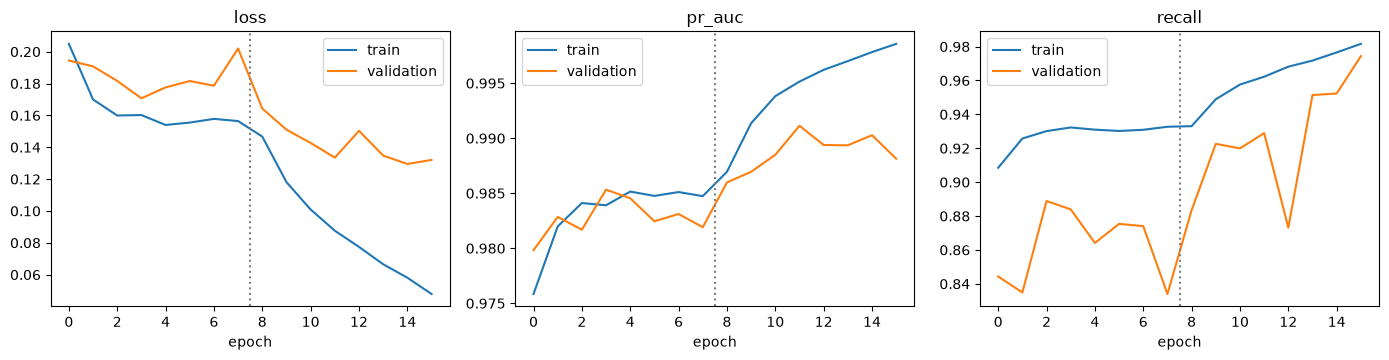

In [9]:
history = {}
started = time.time()

compile_model(HEAD_LR)
head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    callbacks=callbacks(),
    class_weight=class_weight,
)
for key, values in head.history.items():
    history.setdefault(key, []).extend(values)
head_epochs_run = len(head.history["loss"])

if FINE_TUNE_EPOCHS > 0:
    backbone.trainable = True
    for layer in backbone.layers[:-FINE_TUNE_LAYERS]:
        layer.trainable = False
    for layer in backbone.layers:
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False
    compile_model(FINE_TUNE_LR)
    fine = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=FINE_TUNE_EPOCHS,
        callbacks=callbacks(),
        class_weight=class_weight,
    )
    for key, values in fine.history.items():
        history.setdefault(key, []).extend(values)

train_minutes = (time.time() - started) / 60
print(f"Training took {train_minutes:.1f} min")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.7))
for ax, metric in zip(axes, ("loss", "pr_auc", "recall")):
    ax.plot(history[metric], label="train")
    ax.plot(history["val_" + metric], label="validation")
    if FINE_TUNE_EPOCHS > 0:
        ax.axvline(head_epochs_run - 0.5, color="grey", linestyle=":")
    ax.set_xlabel("epoch")
    ax.set_title(metric)
    ax.legend()
plt.tight_layout()
plt.show()

## 9. Select a decision threshold and evaluate Keras

Threshold selection uses **validation only**. Among thresholds whose overall negative
false-positive rate does not exceed `MAX_VALIDATION_FALSE_POSITIVE_RATE` and whose ESP32
camera-domain false-positive rate does not exceed
`MAX_ESP32_VALIDATION_FALSE_POSITIVE_RATE`, it chooses the one with greatest bird recall,
then F1. Raw ESP32 FP/TN counts are retained because the number of held-out camera negatives
is modest. The test split is evaluated only after that choice is frozen.


In [10]:
def binary_metrics(labels, probabilities, threshold):
    labels = np.asarray(labels, dtype=np.int32)
    probabilities = np.asarray(probabilities, dtype=np.float32).reshape(-1)
    predicted = probabilities >= threshold
    tp = int(np.sum((labels == 1) & predicted))
    tn = int(np.sum((labels == 0) & ~predicted))
    fp = int(np.sum((labels == 0) & predicted))
    fn = int(np.sum((labels == 1) & ~predicted))

    def divide(numerator, denominator):
        return float(numerator / denominator) if denominator else float("nan")

    precision = divide(tp, tp + fp)
    recall = divide(tp, tp + fn)
    specificity = divide(tn, tn + fp)
    if np.isfinite(precision) and np.isfinite(recall):
        f1 = divide(2 * precision * recall, precision + recall) if precision + recall else 0.0
    else:
        f1 = float("nan")
    return {
        "threshold": float(threshold),
        "images": int(len(labels)),
        "tp": tp, "tn": tn, "fp": fp, "fn": fn,
        "accuracy": divide(tp + tn, len(labels)),
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "false_positive_rate": divide(fp, fp + tn),
        "f1": f1,
    }


def json_safe(value):
    # Convert NumPy/path values and non-finite floats to strict JSON values.
    if isinstance(value, dict):
        return {str(key): json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (float, np.floating)):
        return None if not np.isfinite(value) else float(value)
    if isinstance(value, Path):
        return str(value)
    return value


keras_probabilities = {
    split_name: model.predict(make_dataset(splits[split_name]), verbose=0).reshape(-1)
    for split_name in ("validation", "test")
}
validation_labels = splits["validation"]["label"].to_numpy()
esp32_validation_mask = (
    splits["validation"]["source_dataset"].to_numpy() == "esp32_capture"
)
if not esp32_validation_mask.any():
    raise RuntimeError("The validation split has no ESP32 captures for threshold selection.")

threshold_grid = np.linspace(0.0, 1.0, 1001)
threshold_rows = []
for threshold in threshold_grid:
    row = binary_metrics(validation_labels, keras_probabilities["validation"], threshold)
    esp32_metrics = binary_metrics(
        validation_labels[esp32_validation_mask],
        keras_probabilities["validation"][esp32_validation_mask],
        threshold,
    )
    row.update({
        "esp32_false_positive_rate": esp32_metrics["false_positive_rate"],
        "esp32_fp": esp32_metrics["fp"],
        "esp32_tn": esp32_metrics["tn"],
    })
    threshold_rows.append(row)
threshold_table = pd.DataFrame(threshold_rows)
eligible = threshold_table[
    (threshold_table["false_positive_rate"] <= MAX_VALIDATION_FALSE_POSITIVE_RATE)
    & (
        threshold_table["esp32_false_positive_rate"]
        <= MAX_ESP32_VALIDATION_FALSE_POSITIVE_RATE
    )
]
if eligible.empty:
    raise RuntimeError(
        "No threshold met both the overall and ESP32 validation false-positive-rate limits."
    )
selected = eligible.sort_values(
    ["recall", "f1", "threshold"], ascending=[False, False, True]
).iloc[0]
SELECTED_THRESHOLD = float(selected["threshold"])
print(f"Selected threshold: {SELECTED_THRESHOLD:.3f}")
selected.to_frame("validation_value")

Selected threshold: 0.818


,validation_value
threshold,0.818000
images,4229.000000
tp,1805.000000
tn,1979.000000
fp,27.000000
fn,418.000000
accuracy,0.894774
precision,0.985262
recall,0.811966
specificity,0.986540


In [11]:
results = []


def record_binary_results(model_name, split_name, probabilities):
    frame = splits[split_name].iloc[: len(probabilities)]
    sources = [("all", np.ones(len(frame), dtype=bool))]
    sources += [
        (source, frame["source_dataset"].to_numpy() == source)
        for source in sorted(frame["source_dataset"].unique())
    ]
    for source, mask in sources:
        metrics = binary_metrics(
            frame.loc[mask, "label"].to_numpy(), np.asarray(probabilities)[mask], SELECTED_THRESHOLD
        )
        results.append({
            "model": model_name, "split": split_name, "source": source, **metrics
        })


for split_name in ("validation", "test"):
    record_binary_results("keras", split_name, keras_probabilities[split_name])

keras_results = pd.DataFrame(results)
keras_results[keras_results["source"] == "all"].round(4)

,model,split,source,threshold,images,tp,tn,fp,fn,accuracy,precision,recall,specificity,false_positive_rate,f1
0,keras,validation,all,0.818,4229,1805,1979,27,418,0.8948,0.9853,0.812,0.9865,0.0135,0.8903
5,keras,test,all,0.818,14241,5954,6719,89,1479,0.8899,0.9853,0.801,0.9869,0.0131,0.8836


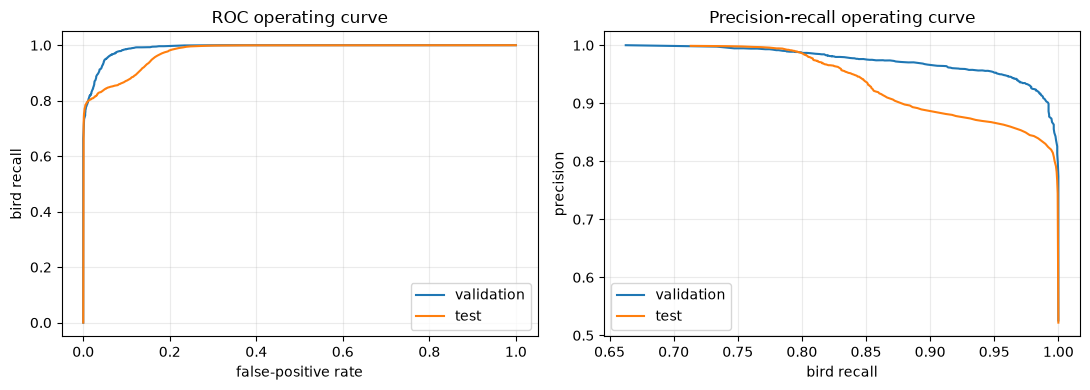

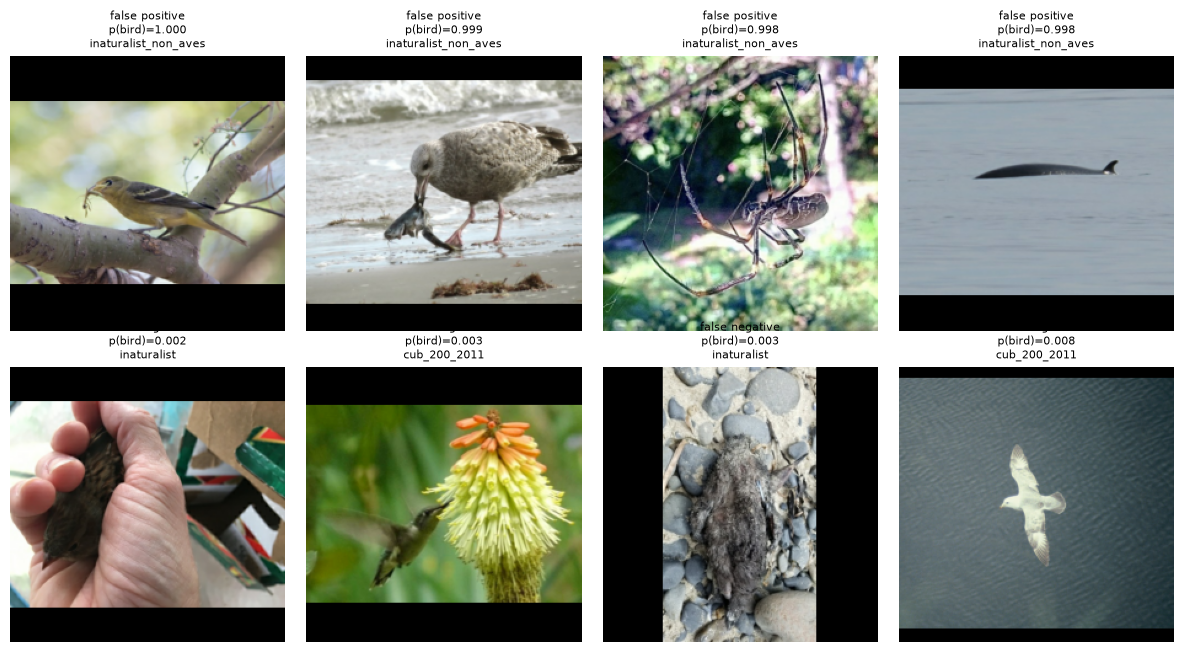

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for split_name, color in (("validation", "tab:blue"), ("test", "tab:orange")):
    labels = splits[split_name]["label"].to_numpy()
    probabilities = keras_probabilities[split_name]
    curve = pd.DataFrame([
        binary_metrics(labels, probabilities, threshold)
        for threshold in np.linspace(0, 1, 201)
    ])
    axes[0].plot(curve["false_positive_rate"], curve["recall"], label=split_name, color=color)
    axes[1].plot(curve["recall"], curve["precision"], label=split_name, color=color)
axes[0].set(xlabel="false-positive rate", ylabel="bird recall", title="ROC operating curve")
axes[1].set(xlabel="bird recall", ylabel="precision", title="Precision-recall operating curve")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

test_frame = splits["test"].copy()
test_frame["bird_probability"] = keras_probabilities["test"]
test_frame["predicted"] = (test_frame["bird_probability"] >= SELECTED_THRESHOLD).astype(int)
mistakes = pd.concat([
    test_frame[(test_frame["label"] == 0) & (test_frame["predicted"] == 1)]
    .sort_values("bird_probability", ascending=False).head(4),
    test_frame[(test_frame["label"] == 1) & (test_frame["predicted"] == 0)]
    .sort_values("bird_probability", ascending=True).head(4),
])
if len(mistakes):
    fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, row in zip(axes.ravel(), mistakes.itertuples(index=False)):
        ax.imshow(load_image(row.path).numpy().astype("uint8"))
        kind = "false positive" if row.label == 0 else "false negative"
        ax.set_title(f"{kind}\np(bird)={row.bird_probability:.3f}\n{row.source_dataset}", fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No test mistakes at the selected threshold.")

## 10. Export Keras, float32 TFLite, and full-integer uint8 TFLite

The representative dataset is sampled only from training images. The int8 converter is
restricted to integer built-in operations and requests uint8 input/output tensors.

In [13]:
keras_path = RUN_DIR / "model.keras"
model.save(keras_path)

saved_model_dir = RUN_DIR / "saved_model"
if hasattr(model, "export"):
    model.export(str(saved_model_dir))
    new_converter = lambda: tf.lite.TFLiteConverter.from_saved_model(str(saved_model_dir))
else:
    new_converter = lambda: tf.lite.TFLiteConverter.from_keras_model(model)

float_path = RUN_DIR / "model_float32.tflite"
float_path.write_bytes(new_converter().convert())

calibration = splits["train"].sample(
    n=min(REPRESENTATIVE_IMAGES, len(splits["train"])), random_state=SEED
)


def representative_dataset():
    for path in calibration["path"]:
        yield [load_image(path)[tf.newaxis, ...]]


converter = new_converter()
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.uint8
converter.inference_output_type = tf.uint8
int8_path = RUN_DIR / "model_int8.tflite"
int8_path.write_bytes(converter.convert())

(RUN_DIR / "labels.txt").write_text("not_bird\nbird\n", encoding="utf-8")
threshold_record = {
    "bird_probability_threshold": SELECTED_THRESHOLD,
    "selection_split": "validation",
    "maximum_validation_false_positive_rate": MAX_VALIDATION_FALSE_POSITIVE_RATE,
    "validation_metrics": binary_metrics(
        validation_labels, keras_probabilities["validation"], SELECTED_THRESHOLD
    ),
}
(RUN_DIR / "threshold.json").write_text(
    json.dumps(json_safe(threshold_record), indent=2, allow_nan=False), encoding="utf-8"
)
shutil.rmtree(saved_model_dir, ignore_errors=True)

for path in (float_path, int8_path):
    print(f"{path.name}: {path.stat().st_size / 1e6:.2f} MB")

INFO:tensorflow:Assets written to: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/runs/isbird_letterbox_224_20261010_173627/saved_model/assets


INFO:tensorflow:Assets written to: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/runs/isbird_letterbox_224_20261010_173627/saved_model/assets


Saved artifact at '/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/runs/isbird_letterbox_224_20261010_173627/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  131784567263632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131784261394384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131784603250576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131784563681104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131784564385232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131784564387728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131784493882768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131783418120528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  131784261849680: TensorSpec(shape=(), dtype=tf.resource, nam

W0000 00:00:1791669419.495798    1832 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1791669419.495853    1832 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1791669419.514595    1832 reader.cc:83] Reading SavedModel from: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/runs/isbird_letterbox_224_20261010_173627/saved_model
I0000 00:00:1791669419.532633    1832 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1791669419.532661    1832 reader.cc:147] Reading SavedModel debug info (if present) from: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/runs/isbird_letterbox_224_20261010_173627/saved_model
I0000 00:00:1791669419.586823    1832 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1791669419.598630    1832 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1791669420.198286    1832 loader.cc:220] Running initialization op on SavedModel bun

model_float32.tflite: 8.89 MB
model_int8.tflite: 2.74 MB


fully_quantize: 0, inference_type: 6, input_inference_type: UINT8, output_inference_type: UINT8
W0000 00:00:1791669454.007783    1832 flatbuffer_export.cc:3851] Skipping runtime version metadata in the model. This will be generated by the exporter.


## 11. Evaluate the exported TFLite models

Quantized tensors are converted using their recorded scale and zero point. Reported
probabilities are therefore on the same 0-1 scale as Keras. Latency is measured on this
machine and is useful for comparing runs, not as a Raspberry Pi benchmark.

In [14]:
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    Interpreter = tf.lite.Interpreter


def run_tflite(model_path, frame):
    interpreter = Interpreter(model_path=str(model_path), num_threads=os.cpu_count())
    interpreter.allocate_tensors()
    inp = interpreter.get_input_details()[0]
    out = interpreter.get_output_details()[0]
    if tuple(inp["shape"]) != (1, IMG_SIZE, IMG_SIZE, 3):
        raise ValueError(f"Unexpected input shape: {inp['shape']}")
    outputs, seconds = [], 0.0
    for path in frame["path"]:
        image = load_image(path).numpy()[None, ...]
        if inp["dtype"] != np.float32:
            scale, zero_point = inp["quantization"]
            if scale <= 0:
                raise ValueError("Quantized input tensor has no usable scale.")
            limits = np.iinfo(inp["dtype"])
            image = np.clip(np.round(image / scale + zero_point), limits.min, limits.max)
        interpreter.set_tensor(inp["index"], image.astype(inp["dtype"]))
        tick = time.perf_counter()
        interpreter.invoke()
        seconds += time.perf_counter() - tick
        result = interpreter.get_tensor(out["index"])[0]
        if out["dtype"] != np.float32:
            scale, zero_point = out["quantization"]
            if scale <= 0:
                raise ValueError("Quantized output tensor has no usable scale.")
            result = (result.astype(np.float32) - zero_point) * scale
        outputs.append(float(np.asarray(result).reshape(-1)[0]))
    details = {
        "input_dtype": np.dtype(inp["dtype"]).name,
        "output_dtype": np.dtype(out["dtype"]).name,
        "input_quantization": tuple(float(x) for x in inp["quantization"]),
        "output_quantization": tuple(float(x) for x in out["quantization"]),
    }
    return np.asarray(outputs), 1000 * seconds / len(frame), details


tflite_info = {}
for model_name, path in (("tflite_float32", float_path), ("tflite_int8", int8_path)):
    tflite_info[model_name] = {"size_mb": path.stat().st_size / 1e6}
    for split_name in ("validation", "test"):
        frame = splits[split_name]
        if TFLITE_EVAL_LIMIT:
            frame = frame.head(TFLITE_EVAL_LIMIT)
        probabilities, ms_per_image, tensor_details = run_tflite(path, frame)
        record_binary_results(model_name, split_name, probabilities)
        reference = keras_probabilities[split_name][: len(probabilities)]
        agreement = np.mean(
            (probabilities >= SELECTED_THRESHOLD) == (reference >= SELECTED_THRESHOLD)
        )
        tflite_info[model_name][split_name] = {
            "images": len(frame),
            "ms_per_image": ms_per_image,
            "decision_agreement_with_keras": float(agreement),
            "mean_absolute_probability_delta": float(np.mean(np.abs(probabilities - reference))),
        }
        tflite_info[model_name]["tensors"] = tensor_details
    print(model_name, json.dumps(tflite_info[model_name], indent=2))

results_table = pd.DataFrame(results)
results_table[results_table["source"] == "all"].round(4)

/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


tflite_float32 {
  "size_mb": 8.894536,
  "validation": {
    "images": 4229,
    "ms_per_image": 2.509837592582237,
    "decision_agreement_with_keras": 1.0,
    "mean_absolute_probability_delta": 0.00017327037041728143
  },
  "tensors": {
    "input_dtype": "float32",
    "output_dtype": "float32",
    "input_quantization": [
      0.0,
      0.0
    ],
    "output_quantization": [
      0.0,
      0.0
    ]
  },
  "test": {
    "images": 14241,
    "ms_per_image": 2.6025332594680424,
    "decision_agreement_with_keras": 0.9999297802120638,
    "mean_absolute_probability_delta": 0.00014499813476635332
  }
}
tflite_int8 {
  "size_mb": 2.736064,
  "validation": {
    "images": 4229,
    "ms_per_image": 2.059979057700516,
    "decision_agreement_with_keras": 0.9867580988413337,
    "mean_absolute_probability_delta": 0.023702372933768465
  },
  "tensors": {
    "input_dtype": "uint8",
    "output_dtype": "uint8",
    "input_quantization": [
      1.0,
      0.0
    ],
    "output_quantiz

,model,split,source,threshold,images,tp,tn,fp,fn,accuracy,precision,recall,specificity,false_positive_rate,f1
0,keras,validation,all,0.818,4229,1805,1979,27,418,0.8948,0.9853,0.8120,0.9865,0.0135,0.8903
5,keras,test,all,0.818,14241,5954,6719,89,1479,0.8899,0.9853,0.8010,0.9869,0.0131,0.8836
10,tflite_float32,validation,all,0.818,4229,1805,1979,27,418,0.8948,0.9853,0.8120,0.9865,0.0135,0.8903
15,tflite_float32,test,all,0.818,14241,5953,6719,89,1480,0.8898,0.9853,0.8009,0.9869,0.0131,0.8836
20,tflite_int8,validation,all,0.818,4229,1807,1971,35,416,0.8934,0.9810,0.8129,0.9826,0.0174,0.8891
25,tflite_int8,test,all,0.818,14241,5951,6701,107,1482,0.8884,0.9823,0.8006,0.9843,0.0157,0.8822


## 12. Save reproducibility metadata and experiment log

In [15]:
results_table.to_csv(RUN_DIR / "results.csv", index=False)
threshold_table.to_csv(RUN_DIR / "validation_thresholds.csv", index=False)


run_config = {
    "run_name": RUN_NAME,
    "created": datetime.now().isoformat(timespec="seconds"),
    "task": "binary bird/not-bird classification",
    "labels": {"0": "not_bird", "1": "bird"},
    "preprocessing": PREPROCESSING,
    "img_size": IMG_SIZE,
    "input": "RGB, 0-255; scaling to [-1, 1] is inside the model",
    "output": "scalar sigmoid bird_probability",
    "selected_threshold": SELECTED_THRESHOLD,
    "maximum_validation_false_positive_rate": MAX_VALIDATION_FALSE_POSITIVE_RATE,
    "maximum_esp32_validation_false_positive_rate": MAX_ESP32_VALIDATION_FALSE_POSITIVE_RATE,
    "backbone": f"MobileNetV2 alpha={BACKBONE_ALPHA} weights={WEIGHTS}",
    "dropout": DROPOUT,
    "batch_size": BATCH_SIZE,
    "head_epochs": HEAD_EPOCHS,
    "head_lr": HEAD_LR,
    "fine_tune_epochs": FINE_TUNE_EPOCHS,
    "fine_tune_layers": FINE_TUNE_LAYERS,
    "fine_tune_lr": FINE_TUNE_LR,
    "epochs_run": len(history["loss"]),
    "augment_flip": AUGMENT_FLIP,
    "augment_color": AUGMENT_COLOR,
    "seed": SEED,
    "negative_to_positive_ratio": NEGATIVE_TO_POSITIVE_RATIO,
    "verify_all_files": VERIFY_ALL_FILES,
    "esp32_capture": {
        "configured_root": ESP32_CAPTURE_ROOT,
        "resolved_root": str(ESP32_CAPTURE_ROOT_RESOLVED),
        "manifest": str(ESP32_MANIFEST_CSV),
        "manifest_sha256": esp32_manifest_sha,
        "manifest_rows": len(esp32_raw),
        "confirmed_rows": len(esp32_confirmed),
        "rejected_rows": len(esp32_raw) - len(esp32_confirmed),
        "validation_dates": sorted(validation_dates),
        "test_dates": sorted(test_dates),
        "training_limit_per_label": ESP32_TRAIN_LIMIT_PER_LABEL,
        "selected_images": {
            name: {
                "bird": int(((esp32_frame["model_split"] == name) & (esp32_frame["label"] == 1)).sum()),
                "not_bird": int(((esp32_frame["model_split"] == name) & (esp32_frame["label"] == 0)).sum()),
            }
            for name in split_names
        },
    },
    "limit_per_class_per_split": LIMIT_PER_CLASS_PER_SPLIT,
    "tflite_eval_limit": TFLITE_EVAL_LIMIT,
    "images": {
        name: {
            "total": len(frame),
            "bird": int((frame["label"] == 1).sum()),
            "not_bird": int((frame["label"] == 0).sum()),
        }
        for name, frame in splits.items()
    },
    "bird_training_manifest": str(BIRD_MANIFEST_CSV),
    "bird_training_manifest_sha256": bird_manifest_sha,
    "isbird_dataset_manifest_sha256": dataset_manifest_sha,
    "inaturalist_metadata": str(metadata_path),
    "inaturalist_metadata_sha256": sha256_file(metadata_path),
    "tensorflow": tf.__version__,
    "train_minutes": round(train_minutes, 1),
    "tflite": tflite_info,
    "results": results,
}
(RUN_DIR / "run_config.json").write_text(
    json.dumps(json_safe(run_config), indent=2, allow_nan=False), encoding="utf-8"
)

all_rows = results_table[results_table["source"] == "all"]
log_row = {
    "run_name": RUN_NAME,
    "created": run_config["created"],
    "preprocessing": PREPROCESSING,
    "img_size": IMG_SIZE,
    "backbone": run_config["backbone"],
    "selected_threshold": SELECTED_THRESHOLD,
    "max_validation_fpr": MAX_VALIDATION_FALSE_POSITIVE_RATE,
    "max_esp32_validation_fpr": MAX_ESP32_VALIDATION_FALSE_POSITIVE_RATE,
    "train_minutes": run_config["train_minutes"],
    "dataset_manifest_sha256": dataset_manifest_sha,
}
for row in all_rows.itertuples(index=False):
    stem = f"{row.model}_{row.split}"
    for metric in ("accuracy", "precision", "recall", "specificity", "false_positive_rate", "f1"):
        log_row[f"{stem}_{metric}"] = getattr(row, metric)
for model_name, info in tflite_info.items():
    log_row[f"{model_name}_size_mb"] = info["size_mb"]
    log_row[f"{model_name}_test_ms_per_image"] = info["test"]["ms_per_image"]

log_path = MODELS_DIR / "isbird_experiments.csv"
log = pd.concat(
    [pd.read_csv(log_path), pd.DataFrame([log_row])], ignore_index=True
) if log_path.exists() else pd.DataFrame([log_row])
log.to_csv(log_path, index=False)

print("Saved run artifacts to", RUN_DIR)
log.tail(10)

Saved run artifacts to /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/runs/isbird_letterbox_224_20261010_173627


,run_name,created,preprocessing,img_size,backbone,selected_threshold,max_validation_fpr,max_esp32_validation_fpr,train_minutes,dataset_manifest_sha256,...,tflite_int8_test_accuracy,tflite_int8_test_precision,tflite_int8_test_recall,tflite_int8_test_specificity,tflite_int8_test_false_positive_rate,tflite_int8_test_f1,tflite_float32_size_mb,tflite_float32_test_ms_per_image,tflite_int8_size_mb,tflite_int8_test_ms_per_image
0,isbird_letterbox_224_20261010_173627,2026-10-10T18:39:31,letterbox,224,MobileNetV2 alpha=1.0 weights=imagenet,0.818,0.05,0.05,11.8,0ccfd57de4bf8cb79ff7d972ecec932dae095ee2a61968...,...,0.888421,0.982337,0.800619,0.984283,0.015717,0.882218,8.894536,2.602533,2.736064,1.971555


## 13. Raspberry Pi inference contract

Use the same geometric preprocessing selected above, then read the scalar output as
`bird_probability`. For a quantized model, dequantize the output using its tensor scale and
zero point exactly as in `run_tflite`.

Do the corresponding input quantization as well: `q = round(pixel / scale + zero_point)`,
clipped to the input dtype. Do not blindly cast resized pixels to uint8 because the exported
input scale is calibration-dependent and is not guaranteed to equal `1.0`.

```python
is_bird = bird_probability >= bird_probability_threshold
confidence = bird_probability if is_bird else 1.0 - bird_probability

return {
    "is_bird": bool(is_bird),
    "label": "bird" if is_bird else "not_bird",
    "confidence": float(confidence),
}
```

Load `bird_probability_threshold` from the exported `threshold.json`; do not silently use
`0.5`. Note that `confidence` above means confidence in the returned binary decision, while
the raw model output always means probability of bird.

### Before deployment

1. Review the per-source ESP32 validation and test metrics, including raw FP/TN counts.
2. Keep future capture bursts/events in one split using a shared `group_id` or session date.
3. Re-select the threshold whenever representative camera data or firmware imaging changes.
4. Preserve an untouched field test set and measure false triggers per camera-day.
5. Copy the chosen `.tflite` file and `threshold.json` to the Pi together.
